# Stock Market Data Analysis: Which Tech Stock Was the Best Investment?

**A beginner-friendly data analysis project using Python, pandas and Plotly**

---

## About This Project

Imagine you could travel back a few years and invest in one of four big technology companies: **Apple, Amazon, Google or Microsoft**. Which one would you choose? Which one would let you sleep peacefully at night, and which one would have made you the most money?

This project answers those questions using several years of real daily stock prices (the dataset runs from 2013 to early 2018). I built it as a fresher data analyst to practise the full analysis workflow: loading data, cleaning it, creating new columns, making charts, and explaining the results in simple words.

## Questions This Project Answers

1. Which stock was the **safest** (the most stable)?
2. Which stock made the **most money**?
3. What would **1 million dollars** invested in the best stock have grown to?
4. What were the **worst crash days**, and how deep were the falls?
5. What is the **long-term trend** of each stock (moving averages)?
6. Do some **months** perform better than others?
7. Do these stocks **move together**? (This matters for diversification.)

## Dataset

- **Source:** *S&P 500 Stock Data* on Kaggle (by Cam Nugent). It has one CSV file per company.
- **Columns:** `date`, `open`, `high`, `low`, `close`, `volume`, `Name` (the company's ticker symbol).
- **Companies used here:** AAPL (Apple), AMZN (Amazon), GOOG (Google) and MSFT (Microsoft).
- **Where to put it:** download the dataset and place the `individual_stocks_5yr` folder inside a `data` folder in the project root.

## Tools Used

Python, pandas, NumPy, Plotly.

## Mini Glossary (new to the stock market? start here)

| Term | Simple meaning |
|---|---|
| **Closing price** | The price of one share at the end of a trading day. |
| **Daily return** | How much the price changed since yesterday, in percent. +2% means the price rose by 2%. |
| **Volatility (risk)** | How wildly the daily returns jump around. Big swings mean higher risk. |
| **Cumulative return** | What 1 dollar invested on day one is worth today. 2.0 means the money doubled. |
| **Moving average** | The average price of the last N days. It smooths out the noise so the trend is easier to see. |
| **Drawdown** | How far a stock has fallen from its highest point so far. |
| **Correlation** | A number from -1 to 1 showing whether two stocks move together. Close to 1 means they usually rise and fall on the same days. |

## What This Notebook Creates

When you run all the cells, the notebook automatically creates a `visuals` folder in the project root containing:

- **9 chart images** (PNG files), ready to use in the README
- **`dashboard.html`**: one interactive page with all the charts, key numbers and findings. Double-click it to open it in your browser.

## How to Run

1. Download the dataset and place it as described above.
2. Install the libraries: `pip install pandas numpy plotly kaleido`
3. Use **Run All** in Jupyter or VS Code. (Saving PNG images needs Google Chrome installed. If it is missing, everything else still works. The notebook will tell you what to do.)

---
## Part 1: Setup and Data Collection

In this part, we prepare our folders, load the daily stock data of four companies and combine them into a single table (a pandas DataFrame).

### 1.1 Import Libraries

In [1]:
# Standard library
import calendar
from pathlib import Path

# Data analysis
import numpy as np
import pandas as pd

# Charts
import plotly.express as px

# Lets us show nicely formatted text inside the notebook
from IPython.display import Markdown, display

### 1.2 Project Settings and Helper Function

This cell does the "housekeeping" for the whole notebook:

- It finds the data folder and creates the `visuals` folder where the charts will be saved.
- It keeps a few settings in one place so they are easy to change.
- It defines `save_chart()`, a small helper that displays a chart and saves it as a PNG image. Because every chart goes through this one function, we do not repeat the saving code nine times.

In [2]:
# ---------------------- Folder locations ----------------------
# This notebook lives inside the "notebooks" folder, so the project root is one level up.
PROJECT_ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
DATA_DIR = PROJECT_ROOT / "data" / "individual_stocks_5yr"
VISUALS_DIR = PROJECT_ROOT / "visuals"
VISUALS_DIR.mkdir(exist_ok=True)  # creates the folder only if it does not exist yet

# ---------------------- Settings you can change ----------------------
INVESTMENT = 1_000_000        # starting money for the investment simulation (in dollars)
USE_COMMON_WINDOW = True      # True = compare all stocks over the same dates (explained in Part 2)
OFFLINE_DASHBOARD = False     # True = embed Plotly inside dashboard.html (bigger file, works without internet)

# One fixed colour per company, so every chart uses the same colours
COLORS = {"AAPL": "#2E86DE", "AMZN": "#F39C12", "GOOG": "#27AE60", "MSFT": "#C0392B"}

# ---------------------- Helper: show and save a chart ----------------------
charts = {}          # keeps every chart so the dashboard can reuse them in Part 12
png_enabled = True   # switches to False if PNG saving is not possible on this computer


def save_chart(fig, file_name, height=520):
    """Show a chart, remember it for the dashboard and save it as a PNG in the visuals folder."""
    global png_enabled

    fig.update_layout(template="plotly_white", height=height)
    if fig.layout.legend.title.text == "Name":  # Plotly names the legend after the column, so rename it
        fig.update_layout(legend_title_text="Company")
    charts[file_name] = fig
    fig.show()

    if png_enabled:
        try:
            fig.write_image(str(VISUALS_DIR / f"{file_name}.png"), width=1200, height=height, scale=2)
        except Exception:
            png_enabled = False
            print(
                "Note: PNG images could not be saved because Kaleido needs Google Chrome.\n"
                "Install Chrome (or run 'plotly_get_chrome' in a terminal) and run the notebook again.\n"
                "The charts and the dashboard still work without it."
            )

### 1.3 Check the Dataset

The dataset has one CSV file per company. Before loading anything, we check that the data folder exists and count the files.

In [3]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data folder not found: {DATA_DIR.resolve()}\n"
        "Download the dataset from Kaggle and place the 'individual_stocks_5yr' folder inside a 'data' folder "
        "in the project root."
    )

print(f"Number of CSV files found: {len(list(DATA_DIR.glob('*.csv')))}")

Number of CSV files found: 505


### 1.4 Select the Companies

The dataset contains hundreds of companies. We will analyse four well-known technology companies. The dictionary below links each ticker symbol to the company's name.

In [4]:
companies = {
    "AAPL": "Apple",
    "AMZN": "Amazon",
    "GOOG": "Google",
    "MSFT": "Microsoft",
}

company_files = {ticker: DATA_DIR / f"{ticker}_data.csv" for ticker in companies}
company_files

{'AAPL': WindowsPath('../data/individual_stocks_5yr/AAPL_data.csv'),
 'AMZN': WindowsPath('../data/individual_stocks_5yr/AMZN_data.csv'),
 'GOOG': WindowsPath('../data/individual_stocks_5yr/GOOG_data.csv'),
 'MSFT': WindowsPath('../data/individual_stocks_5yr/MSFT_data.csv')}

### 1.5 Load and Combine the Data

We read each company's CSV file into its own small table, then stack all four tables on top of each other with `pd.concat`. The result is one DataFrame called `all_data`. The `Name` column tells us which company each row belongs to.

In [5]:
frames = []

for ticker, file_path in company_files.items():
    frames.append(pd.read_csv(file_path))

all_data = pd.concat(frames, ignore_index=True)

### 1.6 Inspect the Combined Data

Let's check the size of the data (rows, columns) and preview the first rows.

In [6]:
all_data.shape

(4752, 7)

In [7]:
all_data.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


---
## Part 2: Data Preparation for Time Series Analysis

Stock data is a **time series**: every row is a price recorded on a specific date. Before analysing trends, we need to make sure that:

- dates are real date objects (not plain text),
- there are no missing, duplicated or impossible values,
- rows are in chronological order for each company,
- all companies are compared over the same period of time.

### 2.1 Check Columns and Data Types

In [8]:
all_data.dtypes

date          str
open      float64
high      float64
low       float64
close     float64
volume      int64
Name          str
dtype: object

### 2.2 Convert the Date Column

The `date` column is currently stored as text. Converting it to the `datetime` type lets us sort chronologically, filter by period and use date tools such as `dt.month_name()` later.

In [9]:
all_data["date"] = pd.to_datetime(all_data["date"])

all_data.dtypes

date      datetime64[us]
open             float64
high             float64
low              float64
close            float64
volume             int64
Name                 str
dtype: object

### 2.3 Data Quality Checks

We run five simple checks. A clean result for each one means we can trust the numbers in the rest of the project.

1. **Missing values:** any empty cells?
2. **Duplicate rows:** any row repeated twice?
3. **Invalid volume:** a stock cannot trade zero or negative shares on a trading day.
4. **Invalid prices:** the lowest price of a day can never be higher than the highest price.
5. **Company names:** do we have exactly the four companies we expect?

In [10]:
print("1. Missing values per column:")
print(all_data.isnull().sum())

print("\n2. Duplicate rows:", all_data.duplicated().sum())

print("\n3. Rows with zero or negative volume:", (all_data["volume"] <= 0).sum())

print("\n4. Rows where low price is higher than high price:", (all_data["low"] > all_data["high"]).sum())

print("\n5. Companies in the data:", list(all_data["Name"].unique()))

1. Missing values per column:
date      0
open      0
high      0
low       0
close     0
volume    0
Name      0
dtype: int64

2. Duplicate rows: 0

3. Rows with zero or negative volume: 0

4. Rows where low price is higher than high price: 0

5. Companies in the data: ['AAPL', 'AMZN', 'GOOG', 'MSFT']


### 2.4 Sort the Data Chronologically

Calculations such as daily returns and moving averages depend on row order. We sort by company first, then by date, so each company's prices run in time order.

In [11]:
all_data = all_data.sort_values(["Name", "date"]).reset_index(drop=True)

### 2.5 Check How Much History Each Company Has

Earlier we saw that the combined data has 4,752 rows. If all four companies had the same number of trading days (1,259 each), we would expect 4 x 1,259 = 5,036 rows. The gap is a hint that **one company has a shorter history than the others**. Let's check the first date, last date and number of trading days for each company.

In [12]:
coverage = all_data.groupby("Name")["date"].agg(
    first_date="min",
    last_date="max",
    trading_days="count",
)
coverage

,first_date,last_date,trading_days
Name,,,
AAPL,2013-02-08,2018-02-07,1259
AMZN,2013-02-08,2018-02-07,1259
GOOG,2014-03-27,2018-02-07,975
MSFT,2013-02-08,2018-02-07,1259


### 2.6 Compare Every Stock Over the Same Period

If one company only starts later, comparing it with the others is not fair. A stock that has been recorded for fewer years had fewer chances to grow and fewer chances to crash. This would quietly change answers such as "which stock made the most money" and "which stock is the safest".

To make the comparison fair, we keep only the dates where **all four companies have data**: from the *latest* start date to the *earliest* end date.

This is controlled by the `USE_COMMON_WINDOW` setting in Part 1. Set it to `False` if you want to use each company's full history instead. Just remember that the stocks are then not measured over identical dates.

In [13]:
common_start = coverage["first_date"].max()
common_end = coverage["last_date"].min()

if USE_COMMON_WINDOW:
    inside_window = (all_data["date"] >= common_start) & (all_data["date"] <= common_end)
    all_data = all_data[inside_window].reset_index(drop=True)

print(f"Analysis period: {all_data['date'].min():%d %b %Y} to {all_data['date'].max():%d %b %Y}")
print("\nTrading days per company in the analysis:")
print(all_data.groupby("Name")["date"].count())

Analysis period: 27 Mar 2014 to 07 Feb 2018

Trading days per company in the analysis:
Name
AAPL    975
AMZN    975
GOOG    975
MSFT    975
Name: date, dtype: int64


---
## Part 3: Which Is the Safest Stock to Invest In?

In finance, **risk** is commonly measured by **volatility**: how much a stock's daily returns jump around. We calculate each company's daily return, then compare the standard deviation of those returns. The stock with the **lowest** standard deviation has the most stable price.

### 3.1 Calculate Daily Returns

The daily return is the percentage change in the closing price compared to the previous day:

`daily return = (today's close - yesterday's close) / yesterday's close`

We use `groupby('Name')` so that each company's returns are calculated separately and one company's prices never mix with another's. The first day of each company has no "yesterday", so its return is empty (`NaN`). That is expected.

In [14]:
all_data["daily_return"] = all_data.groupby("Name")["close"].pct_change()

all_data[["Name", "date", "close", "daily_return"]].head()

,Name,date,close,daily_return
0,AAPL,2014-03-27,76.7799,NaN
1,AAPL,2014-03-28,76.6942,-0.001116
2,AAPL,2014-03-31,76.6771,-0.000223
3,AAPL,2014-04-01,77.3785,0.009147
4,AAPL,2014-04-02,77.5071,0.001662


### 3.2 Measure Risk (Volatility)

The standard deviation of daily returns shows how widely each stock's returns swing. A higher value means higher risk. We multiply by 100 to read it as a percentage.

In [15]:
risk = all_data.groupby("Name")["daily_return"].std()

(risk * 100).round(3)

Name
AAPL    1.433
AMZN    1.844
GOOG    1.407
MSFT    1.375
Name: daily_return, dtype: float64

### 3.3 Identify the Safest and the Riskiest Stock

The safest stock is the one with the lowest volatility. The riskiest is the one with the highest.

In [16]:
safest_stock = risk.idxmin()
riskiest_stock = risk.idxmax()

print(f"Safest stock:   {safest_stock} (daily volatility {risk.min() * 100:.2f}%)")
print(f"Riskiest stock: {riskiest_stock} (daily volatility {risk.max() * 100:.2f}%)")

Safest stock:   MSFT (daily volatility 1.38%)
Riskiest stock: AMZN (daily volatility 1.84%)


### 3.4 Visualize the Risk

**Chart 1.** A bar chart makes the comparison easy. The shorter the bar, the calmer the stock.

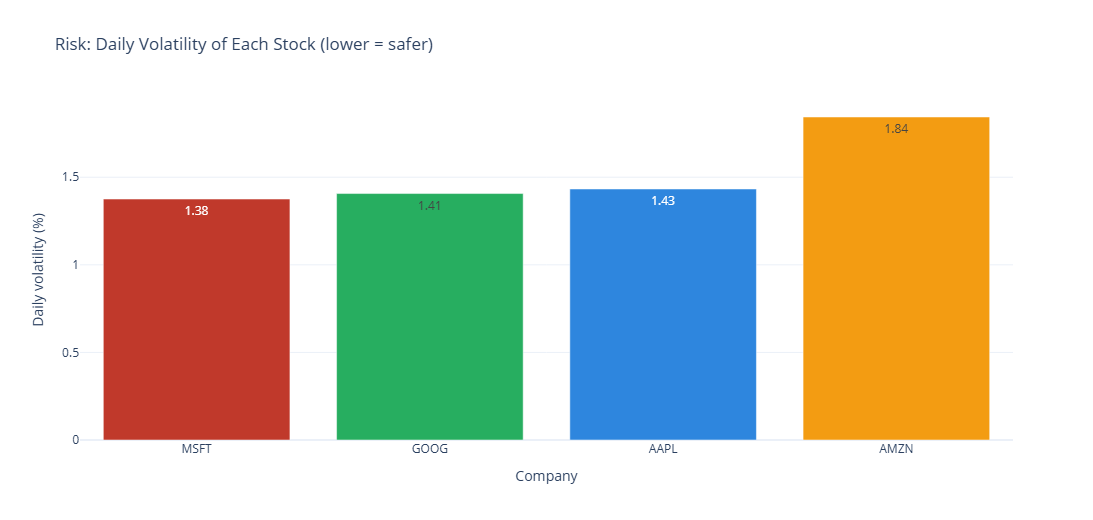

Note: PNG images could not be saved because Kaleido needs Google Chrome.
Install Chrome (or run 'plotly_get_chrome' in a terminal) and run the notebook again.
The charts and the dashboard still work without it.


In [17]:
risk_df = (risk * 100).rename("volatility_pct").reset_index().sort_values("volatility_pct")

fig = px.bar(
    risk_df,
    x="Name",
    y="volatility_pct",
    color="Name",
    color_discrete_map=COLORS,
    text_auto=".2f",
    title="Risk: Daily Volatility of Each Stock (lower = safer)",
    labels={"Name": "Company", "volatility_pct": "Daily volatility (%)"},
)
fig.update_layout(showlegend=False)

save_chart(fig, "01_risk_volatility")

**How to read this chart:** each bar shows how much a stock's daily return typically moves up or down. Differences between the safer stocks can be small, so look at the numbers and not only at the bar heights.

---
## Part 4: Which Stock Made the Most Money?

Volatility tells us how risky a stock is, but not how profitable it was. To measure profit, we use the **cumulative return**: the value at the end of the period of 1 dollar invested on the first day.

### 4.1 Calculate Cumulative Returns

Each day's growth factor is `1 + daily_return`. For example, a +2% day has a factor of 1.02 and a -3% day has a factor of 0.97. Multiplying these factors day after day (`cumprod`) shows how an investment compounds over time.

The first day has no return, so we fill it with 0 (a factor of exactly 1). That way every stock starts at 1.0, which means "1 dollar on day one". We group by company so each stock is calculated on its own. The last value of each group is its final result.

In [18]:
growth_factor = 1 + all_data["daily_return"].fillna(0)
all_data["cumulative_return"] = growth_factor.groupby(all_data["Name"]).cumprod()

final_returns = all_data.groupby("Name")["cumulative_return"].last()

final_returns.round(2)

Name
AAPL    2.08
AMZN    4.19
GOOG    1.88
MSFT    2.28
Name: cumulative_return, dtype: float64

### 4.2 Find the Best-Performing Stock

The stock with the highest final cumulative return made the most money.

In [19]:
best_stock = final_returns.idxmax()
worst_performer = final_returns.idxmin()

print(f"Best performer:  {best_stock} (1 dollar became {final_returns.max():.2f} dollars)")
print(f"Weakest performer: {worst_performer} (1 dollar became {final_returns.min():.2f} dollars)")

Best performer:  AMZN (1 dollar became 4.19 dollars)
Weakest performer: GOOG (1 dollar became 1.88 dollars)


### 4.3 Visualize the Growth Over Time

**Chart 2.** This line chart shows how 1 dollar invested in each stock on the first day would have grown. The dotted line at 1.0 is the break-even level: below it, the investment is losing money.

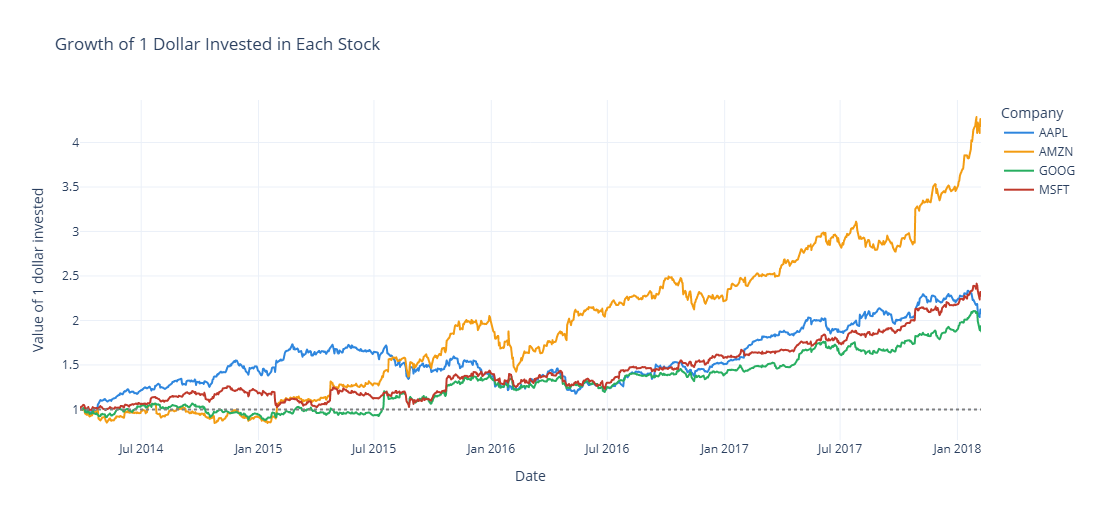

In [20]:
fig = px.line(
    all_data,
    x="date",
    y="cumulative_return",
    color="Name",
    color_discrete_map=COLORS,
    title="Growth of 1 Dollar Invested in Each Stock",
    labels={"date": "Date", "cumulative_return": "Value of 1 dollar invested"},
)
fig.add_hline(y=1, line_dash="dot", line_color="grey")

save_chart(fig, "02_growth_of_one_dollar")

### 4.4 Visualize the Final Result

**Chart 3.** The same information as a simple ranking: the final value of 1 dollar at the end of the period.

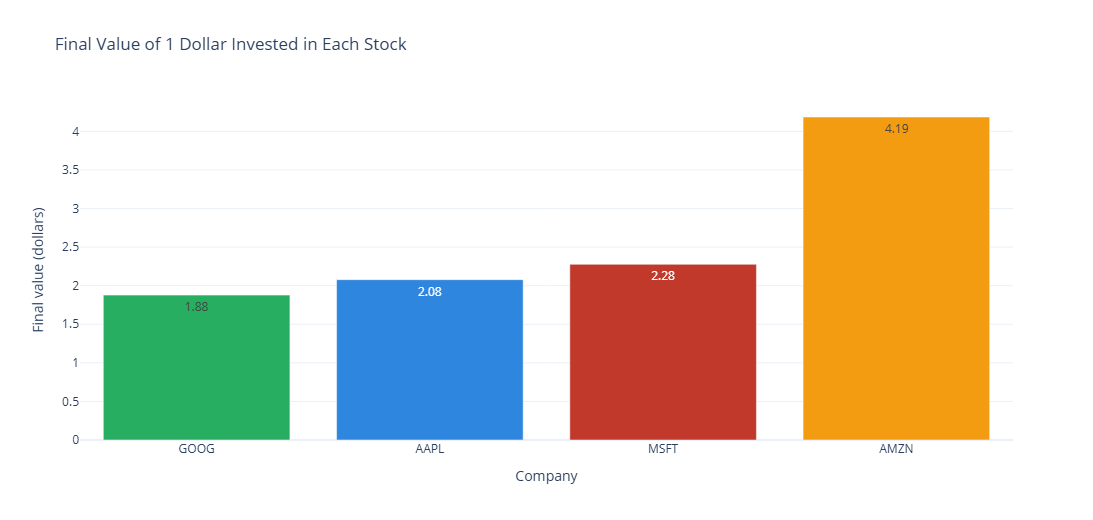

In [21]:
final_df = final_returns.rename("final_value").reset_index().sort_values("final_value")

fig = px.bar(
    final_df,
    x="Name",
    y="final_value",
    color="Name",
    color_discrete_map=COLORS,
    text_auto=".2f",
    title="Final Value of 1 Dollar Invested in Each Stock",
    labels={"Name": "Company", "final_value": "Final value (dollars)"},
)
fig.update_layout(showlegend=False)

save_chart(fig, "03_final_value")

---
## Part 5: Risk vs Return

So far we looked at risk (Part 3) and profit (Part 4) separately. Investors care about both at the same time. A scatter plot puts each stock on one map:

- **Left to right:** more risk.
- **Bottom to top:** more profit.

The ideal stock sits in the **top-left corner**: high profit with low risk.

**Chart 4.**

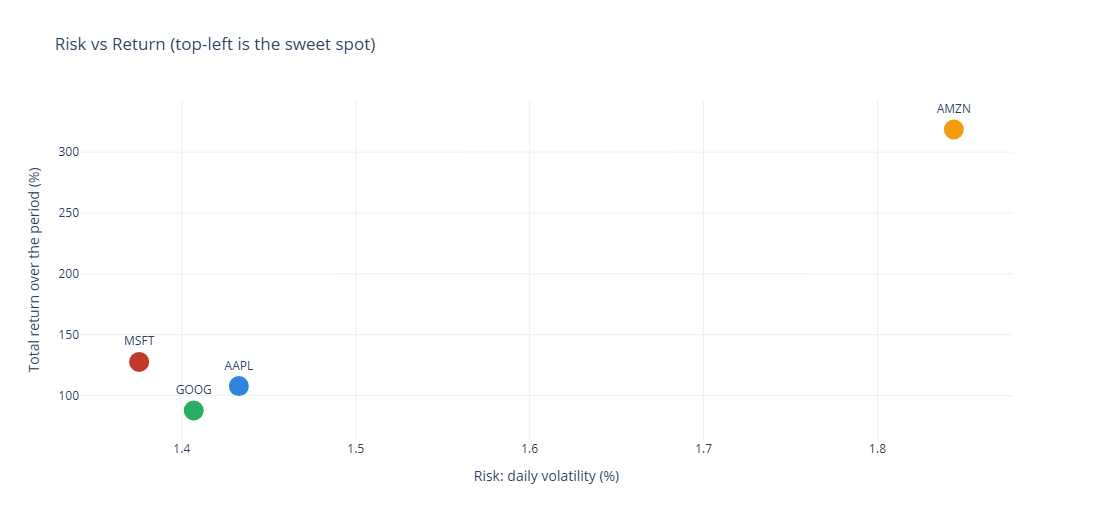

In [22]:
risk_return = pd.DataFrame({
    "volatility_pct": risk * 100,
    "total_return_pct": (final_returns - 1) * 100,
}).reset_index()

fig = px.scatter(
    risk_return,
    x="volatility_pct",
    y="total_return_pct",
    color="Name",
    text="Name",
    color_discrete_map=COLORS,
    title="Risk vs Return (top-left is the sweet spot)",
    labels={
        "volatility_pct": "Risk: daily volatility (%)",
        "total_return_pct": "Total return over the period (%)",
    },
)
fig.update_traces(marker=dict(size=20), textposition="top center")
fig.update_layout(showlegend=False)

save_chart(fig, "04_risk_vs_return")

**How to read this chart:** if the stock with the highest return is also far to the right, then its extra profit came with extra risk. Higher reward and lower risk rarely come together.

---
## Part 6: 1 Million Investment Simulation

What would 1 million dollars invested in the best-performing stock have grown to? We use the cumulative return from Part 4 to simulate the value of the investment on every day.

### 6.1 Filter the Data and Calculate the Investment Value

We keep only the rows of the best-performing stock. We use `.copy()` so that we are working on our own separate table, and then multiply the cumulative return by the starting investment to get the portfolio value on each day.

In [23]:
df_best = all_data[all_data["Name"] == best_stock].copy()
df_best["investment_value"] = df_best["cumulative_return"] * INVESTMENT

df_best[["date", "close", "cumulative_return", "investment_value"]].head()

,date,close,cumulative_return,investment_value
975,2014-03-27,338.470,1.000000,1.000000e+06
976,2014-03-28,338.290,0.999468,9.994682e+05
977,2014-03-31,336.365,0.993781,9.937808e+05
978,2014-04-01,342.990,1.013354,1.013354e+06
979,2014-04-02,341.960,1.010311,1.010311e+06


### 6.2 Final Value of the Investment

We also check the *lowest* value the investment reached. This is an honest reminder that even the best stock had periods where an investor would have been losing money.

In [24]:
start_date = df_best["date"].iloc[0]
end_date = df_best["date"].iloc[-1]
final_value = df_best["investment_value"].iloc[-1]
lowest_value = df_best["investment_value"].min()

print(f"Invested on {start_date:%d %b %Y}: ${INVESTMENT:,.0f} in {best_stock}")
print(f"Value on {end_date:%d %b %Y}:    ${final_value:,.0f}")
print(f"Lowest value along the way:   ${lowest_value:,.0f}")

Invested on 27 Mar 2014: $1,000,000 in AMZN
Value on 07 Feb 2018:    $4,185,836
Lowest value along the way:   $847,786


### 6.3 Visualize the Investment Growth

**Chart 5.** The line shows the value of the investment day by day.

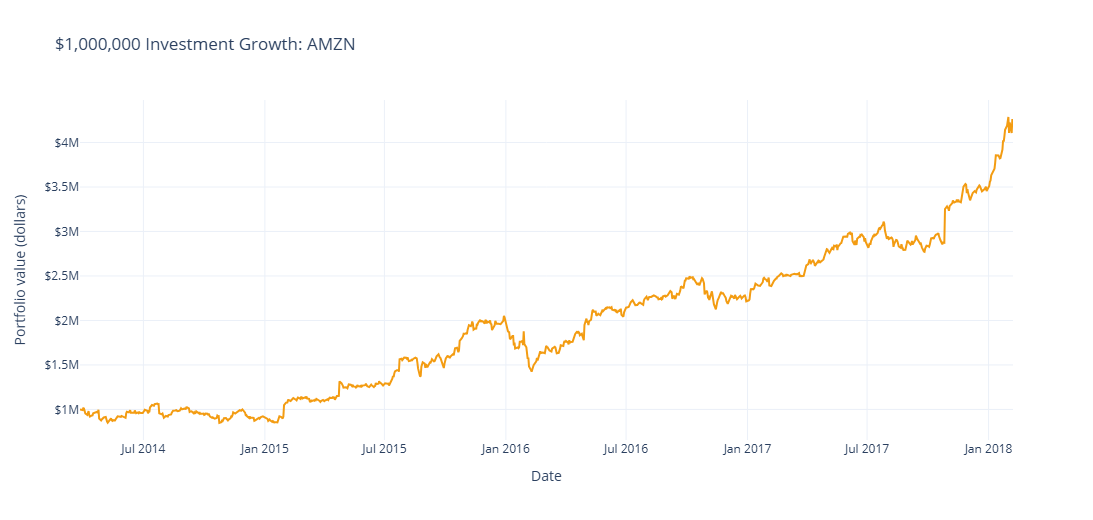

In [25]:
fig = px.line(
    df_best,
    x="date",
    y="investment_value",
    title=f"${INVESTMENT:,.0f} Investment Growth: {best_stock}",
    labels={"date": "Date", "investment_value": "Portfolio value (dollars)"},
    color_discrete_sequence=[COLORS[best_stock]],
)
fig.update_yaxes(tickprefix="$")

save_chart(fig, "05_million_dollar_growth")

---
## Part 7: Crash Days

Volatility gives one average number for risk, but investors also remember the **worst days**. In this part, we find the five biggest single-day losses of each stock and compare them. We also measure the longest "pain" an investor would have felt, using the drawdown.

### 7.1 Worst Days of One Stock (AAPL)

We start with one company to understand the method. `nsmallest(5, 'daily_return')` returns the five rows with the lowest (most negative) daily returns.

In [26]:
all_data[all_data["Name"] == "AAPL"].nsmallest(5, "daily_return")[["Name", "date", "close", "daily_return"]]

,Name,date,close,daily_return
462,AAPL,2016-01-27,93.42,-0.065707
525,AAPL,2016-04-27,97.82,-0.062578
354,AAPL,2015-08-21,105.76,-0.061163
346,AAPL,2015-08-11,113.49,-0.052038
361,AAPL,2015-09-01,107.72,-0.044697


### 7.2 Worst Days of Every Stock

We repeat the same search for each company. First we sort all rows by `daily_return` from the lowest (worst) to the highest. Then `groupby('Name').head(5)` keeps the first five rows of each company, which are its five worst days. Finally, we sort by company name for a tidy table and keep only the columns we need.

In [27]:
worst_days = (
    all_data.sort_values("daily_return")
    .groupby("Name")
    .head(5)
    .sort_values(["Name", "daily_return"])[["Name", "date", "daily_return"]]
    .copy()
)

worst_days

,Name,date,daily_return
462,AAPL,2016-01-27,-0.065707
525,AAPL,2016-04-27,-0.062578
354,AAPL,2015-08-21,-0.061163
346,AAPL,2015-08-11,-0.052038
361,AAPL,2015-09-01,-0.044697
995,AMZN,2014-04-25,-0.098828
1058,AMZN,2014-07-25,-0.096484
1122,AMZN,2014-10-24,-0.083403
1439,AMZN,2016-01-29,-0.076100
1444,AMZN,2016-02-05,-0.063645


### 7.3 Create a Readable Label

If we put the dates on the x-axis, the crash days would be scattered across several years and the bars would become very thin. Instead, we create a text label that combines the company and the date (for example `AAPL | 2015-08-21`) and use one bar per crash day.

In [28]:
worst_days["crash_label"] = worst_days["Name"] + " | " + worst_days["date"].dt.strftime("%Y-%m-%d")

worst_days.head()

,Name,date,daily_return,crash_label
462,AAPL,2016-01-27,-0.065707,AAPL | 2016-01-27
525,AAPL,2016-04-27,-0.062578,AAPL | 2016-04-27
354,AAPL,2015-08-21,-0.061163,AAPL | 2015-08-21
346,AAPL,2015-08-11,-0.052038,AAPL | 2015-08-11
361,AAPL,2015-09-01,-0.044697,AAPL | 2015-09-01


### 7.4 Visualize the Crash Days

**Chart 6.** Each bar is one crash day, coloured by company. Every bar points downward because every bar is a loss.

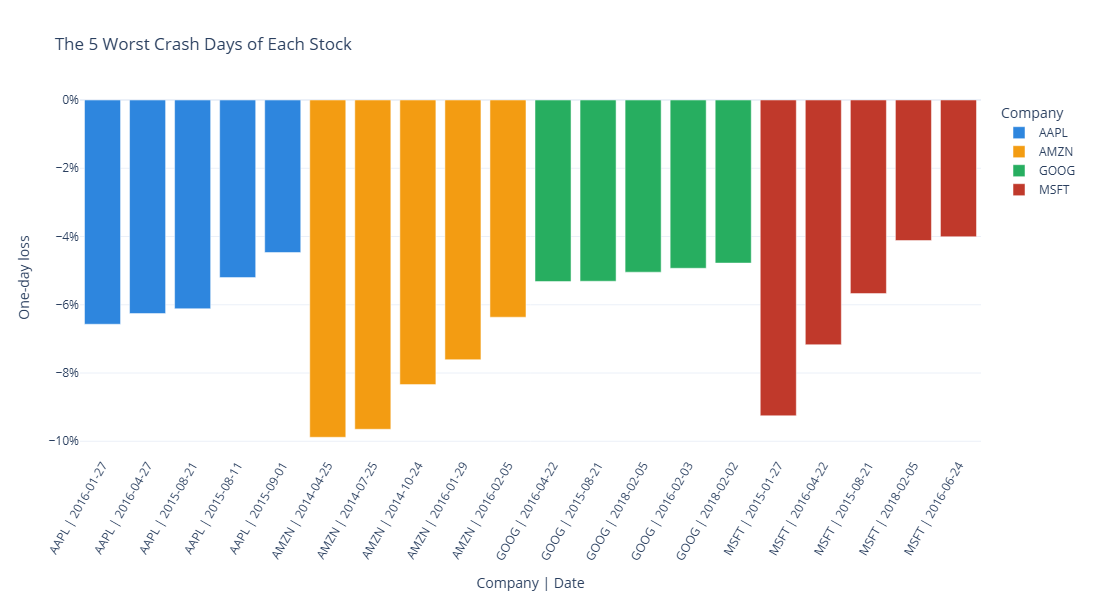

In [29]:
fig = px.bar(
    worst_days,
    x="crash_label",
    y="daily_return",
    color="Name",
    color_discrete_map=COLORS,
    title="The 5 Worst Crash Days of Each Stock",
    labels={"crash_label": "Company | Date", "daily_return": "One-day loss"},
)
fig.update_yaxes(tickformat=".0%")
fig.update_xaxes(tickangle=-60)

save_chart(fig, "06_crash_days", height=600)

### 7.5 Did Several Stocks Crash on the Same Day?

If the same date appears in the worst-day list of more than one company, the fall was probably caused by something that affected the whole market, not just one company. Let's check.

In [30]:
shared_crashes = worst_days.groupby("date")["Name"].apply(list)
shared_crashes = shared_crashes[shared_crashes.apply(len) > 1]

if shared_crashes.empty:
    print("No date appears in more than one company's worst-day list.")
else:
    for crash_date, names in shared_crashes.items():
        print(f"{crash_date:%d %b %Y}: {', '.join(names)}")

21 Aug 2015: AAPL, GOOG, MSFT
22 Apr 2016: GOOG, MSFT
05 Feb 2018: GOOG, MSFT


### 7.6 Measure the Maximum Drawdown

A single bad day is one thing, but a long slide is another. The **drawdown** shows how far a stock is below its highest price so far.

- `cummax()` gives the highest value reached up to each day.
- `cumulative_return / highest value - 1` gives the fall from that peak (0% = at the peak, -30% = 30% below the peak).
- The **maximum drawdown** is the deepest fall in the whole period.

In [31]:
all_data["running_peak"] = all_data.groupby("Name")["cumulative_return"].cummax()
all_data["drawdown"] = all_data["cumulative_return"] / all_data["running_peak"] - 1

max_drawdown = all_data.groupby("Name")["drawdown"].min()

(max_drawdown * 100).round(2)

Name
AAPL   -32.08
AMZN   -30.53
GOOG   -17.37
MSFT   -18.79
Name: drawdown, dtype: float64

---
## Part 8: Moving Average (Trend Analysis)

Daily stock prices move up and down constantly, which makes the overall trend hard to see. A **moving average** smooths these fluctuations by averaging the closing price over the last N days. We calculate a 20-day (short-term) and a 50-day (medium-term) moving average for each stock.

### 8.1 Calculate the Moving Averages

`rolling(20).mean()` averages each day's closing price with the previous 19 days. A longer window (50 days) reacts more slowly, so it shows the longer-term trend. We use `groupby('Name')` so that one company's prices never mix into another company's average.

The first 19 (or 49) days of each company have no moving average yet because there are not enough previous days. They stay empty (`NaN`) and that is normal.

In [32]:
all_data["MA20"] = all_data.groupby("Name")["close"].transform(lambda prices: prices.rolling(20).mean())
all_data["MA50"] = all_data.groupby("Name")["close"].transform(lambda prices: prices.rolling(50).mean())

all_data[["Name", "date", "close", "MA20", "MA50"]].dropna().head()

,Name,date,close,MA20,MA50
49,AAPL,2014-06-06,92.2242,87.937730,82.413242
50,AAPL,2014-06-09,93.7000,88.440290,82.751644
51,AAPL,2014-06-10,94.2500,88.918295,83.102760
52,AAPL,2014-06-11,93.8600,89.370155,83.446418
53,AAPL,2014-06-12,92.2900,89.742730,83.744648


### 8.2 Reshape the Data for Plotting

To draw three lines (price, 20-day average, 50-day average) for four companies, we reshape the table from "wide" to "long" with `melt`. Each row then holds one date, one company, one line name and one value. This is the format Plotly likes best.

In [33]:
line_names = {"close": "Closing price", "MA20": "20-day average", "MA50": "50-day average"}

ma_long = all_data.melt(
    id_vars=["date", "Name"],
    value_vars=list(line_names),
    var_name="line",
    value_name="price",
)
ma_long["line"] = ma_long["line"].map(line_names)

ma_long.head()

,date,Name,line,price
0,2014-03-27,AAPL,Closing price,76.7799
1,2014-03-28,AAPL,Closing price,76.6942
2,2014-03-31,AAPL,Closing price,76.6771
3,2014-04-01,AAPL,Closing price,77.3785
4,2014-04-02,AAPL,Closing price,77.5071


### 8.3 Plot the Price with Its Moving Averages

**Chart 7.** One small chart per company. Each company has its own price scale, because the share prices are very different (a Google share costs far more than a Microsoft share).

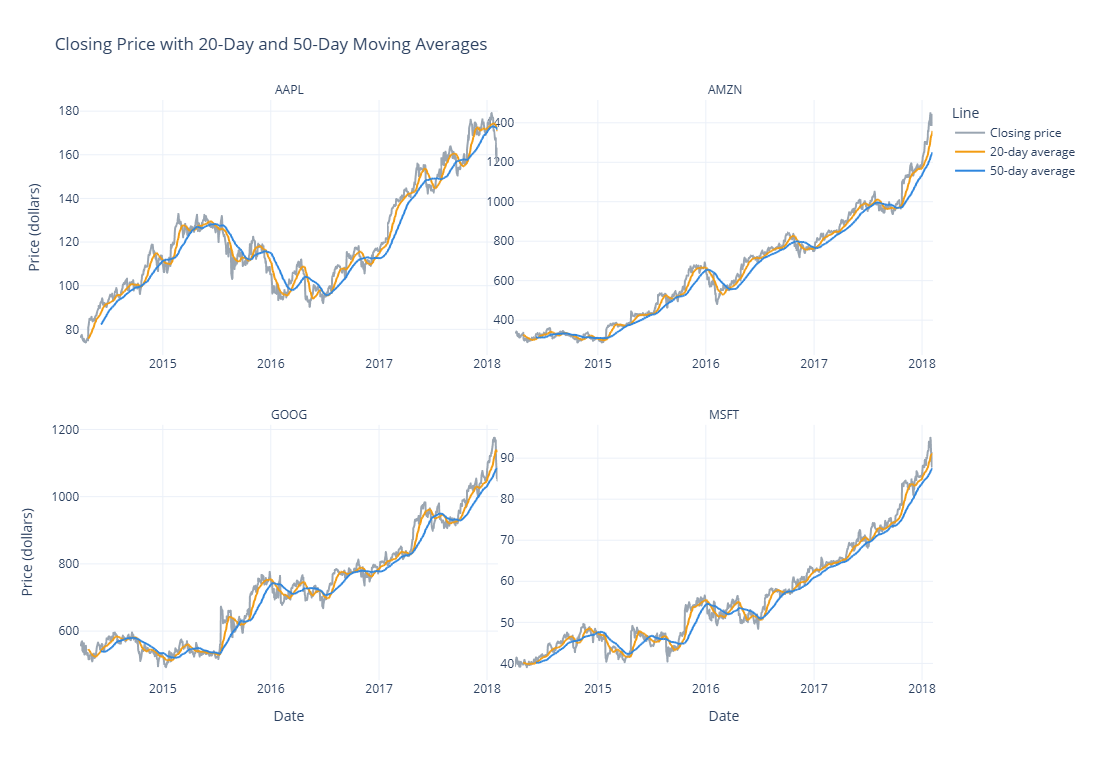

In [34]:
fig = px.line(
    ma_long,
    x="date",
    y="price",
    color="line",
    facet_col="Name",
    facet_col_wrap=2,
    facet_row_spacing=0.12,
    title="Closing Price with 20-Day and 50-Day Moving Averages",
    labels={"date": "Date", "price": "Price (dollars)", "line": "Line"},
    color_discrete_sequence=["#9AA5B1", "#F39C12", "#2E86DE"],
)
fig.update_yaxes(matches=None, showticklabels=True)
fig.update_xaxes(showticklabels=True)
fig.for_each_annotation(lambda note: note.update(text=note.text.split("=")[-1]))

save_chart(fig, "07_moving_averages", height=760)

**How to read these charts:** when the price stays above its moving averages, the stock is generally in an uptrend. When it falls below them, the trend is weakening. Traders also watch the moments when the short average (20-day) crosses the long average (50-day), but we are only describing the trend here, not predicting the future.

---
## Part 9: Do Some Months Perform Better Than Others?

Do stocks perform better in certain months of the year? To find out, we group the daily returns by calendar month and compare the **average daily return** of each month for every stock. This kind of repeating pattern is called **seasonality**.

### 9.1 Extract the Month Name

`dt.month_name()` converts each date into the name of its month (for example `2015-08-24` becomes `August`). This only works because we converted the `date` column to a datetime type in Part 2.

In [35]:
all_data["month_name"] = all_data["date"].dt.month_name()

all_data[["date", "month_name"]].head()

,date,month_name
0,2014-03-27,March
1,2014-03-28,March
2,2014-03-31,March
3,2014-04-01,April
4,2014-04-02,April


### 9.2 Calculate the Average Daily Return per Month

We group by company and month, then take the mean of the daily returns. `reset_index()` turns the grouped result back into a regular table so that it can be plotted. We also convert the return to a percentage.

In [36]:
monthly_returns = (
    all_data.groupby(["Name", "month_name"])["daily_return"]
    .mean()
    .mul(100)
    .rename("avg_daily_return_pct")
    .reset_index()
)

monthly_returns.head()

,Name,month_name,avg_daily_return_pct
0,AAPL,April,-0.048693
1,AAPL,August,0.142182
2,AAPL,December,-0.179917
3,AAPL,February,0.264319
4,AAPL,January,0.038965


### 9.3 Visualize Average Returns by Month

**Chart 8.** A grouped bar chart places the four stocks side by side for every month. We force the months into calendar order (January to December) because otherwise they would appear in alphabetical order.

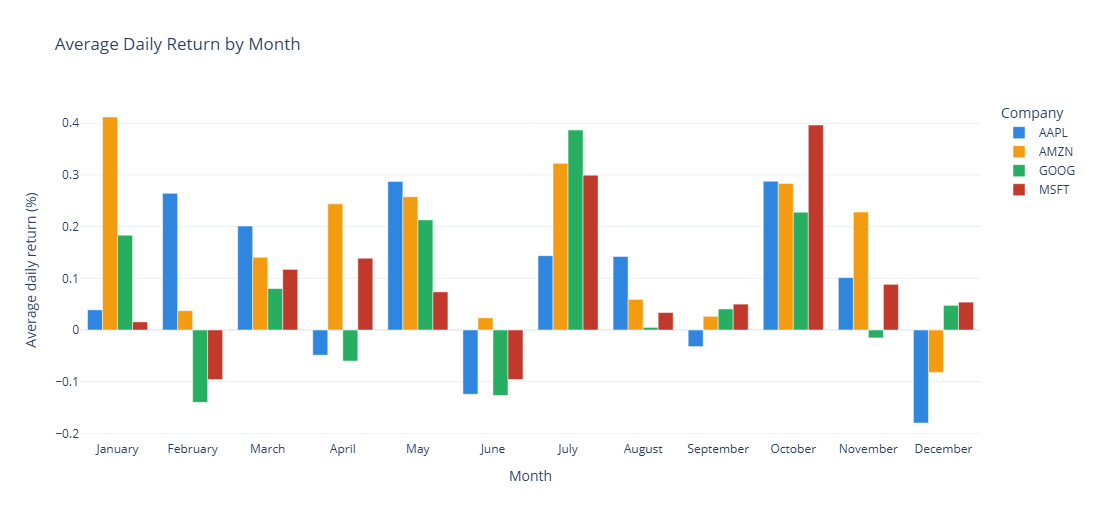

In [37]:
month_order = list(calendar.month_name)[1:]

fig = px.bar(
    monthly_returns,
    x="month_name",
    y="avg_daily_return_pct",
    color="Name",
    barmode="group",
    color_discrete_map=COLORS,
    title="Average Daily Return by Month",
    labels={"month_name": "Month", "avg_daily_return_pct": "Average daily return (%)"},
)
fig.update_xaxes(categoryorder="array", categoryarray=month_order)

save_chart(fig, "08_monthly_seasonality")

### 9.4 The Best and the Worst Month of Each Stock

In [38]:
best_months = monthly_returns.loc[monthly_returns.groupby("Name")["avg_daily_return_pct"].idxmax()]
worst_months = monthly_returns.loc[monthly_returns.groupby("Name")["avg_daily_return_pct"].idxmin()]

print("Best month for each stock:")
print(best_months.round(3).to_string(index=False))

print("\nWorst month for each stock:")
print(worst_months.round(3).to_string(index=False))

Best month for each stock:
Name month_name  avg_daily_return_pct
AAPL    October                 0.288
AMZN    January                 0.412
GOOG       July                 0.387
MSFT    October                 0.396

Worst month for each stock:
Name month_name  avg_daily_return_pct
AAPL   December                -0.180
AMZN   December                -0.082
GOOG   February                -0.140
MSFT   February                -0.096


**A word of caution:** our data covers only a few years, so each month is based on just a handful of observations of that month. A pattern that looks strong here can easily be a coincidence. These results are interesting to explore, but they are **not** a reliable rule for choosing when to invest.

---
## Part 10: Do the Stocks Move Together?

If you own several stocks, you hope that they do not all fall on the same day. That idea is called **diversification**. The **correlation** between two stocks' daily returns tells us how much they move together:

- close to **1**: they usually rise and fall together,
- close to **0**: they move independently,
- close to **-1**: when one rises, the other usually falls.

In [39]:
returns_wide = all_data.pivot(index="date", columns="Name", values="daily_return").dropna()
correlation = returns_wide.corr()

correlation.round(2)

Name,AAPL,AMZN,GOOG,MSFT
Name,,,,
AAPL,1.00,0.36,0.42,0.47
AMZN,0.36,1.00,0.59,0.47
GOOG,0.42,0.59,1.00,0.58
MSFT,0.47,0.47,0.58,1.00


**Chart 9.** A heatmap makes the table easier to read. Darker colour means a stronger connection.

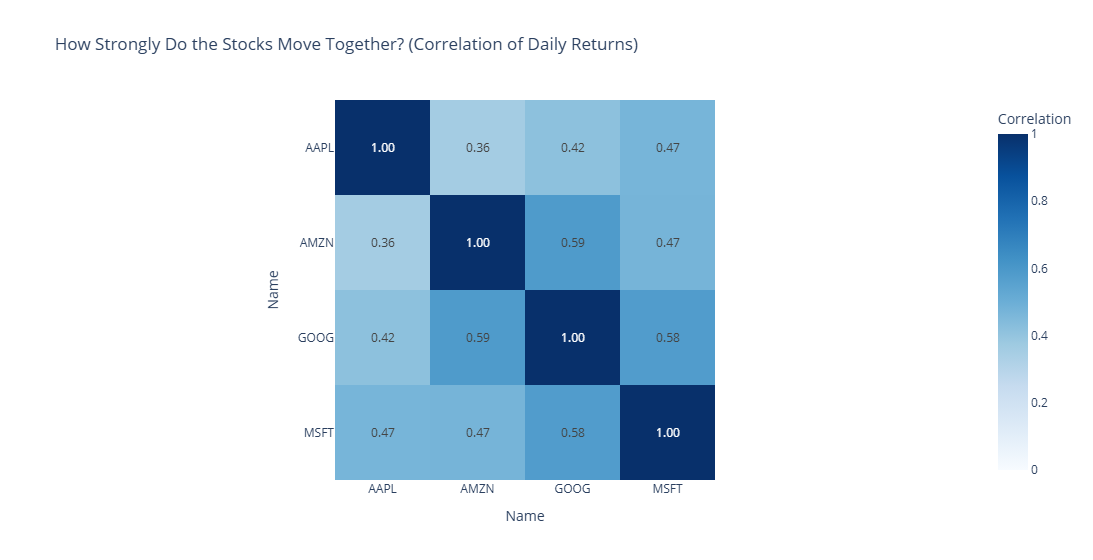

In [40]:
fig = px.imshow(
    correlation,
    text_auto=".2f",
    color_continuous_scale="Blues",
    zmin=min(0, correlation.min().min()),
    zmax=1,
    title="How Strongly Do the Stocks Move Together? (Correlation of Daily Returns)",
    labels={"color": "Correlation"},
)

save_chart(fig, "09_correlation_heatmap", height=560)

---
## Part 11: Summary Scorecard and Key Findings

Now we collect everything into one table, then let the code write the key findings for us. Because the sentences are generated from the results, they always match the numbers, even if the data or settings change.

### 11.1 Scorecard

In [41]:
first_close = all_data.groupby("Name")["close"].first()
last_close = all_data.groupby("Name")["close"].last()

scorecard = pd.DataFrame({
    "Company": pd.Series(companies),
    "Start price ($)": first_close,
    "End price ($)": last_close,
    "Final value of $1": final_returns,
    "Total return (%)": (final_returns - 1) * 100,
    "Daily volatility (%)": risk * 100,
    "Worst day (%)": all_data.groupby("Name")["daily_return"].min() * 100,
    "Max drawdown (%)": max_drawdown * 100,
}).round(2)
scorecard.index.name = "Ticker"

scorecard

,Company,Start price ($),End price ($),Final value of $1,Total return (%),Daily volatility (%),Worst day (%),Max drawdown (%)
Ticker,,,,,,,,
AAPL,Apple,76.78,159.54,2.08,107.79,1.43,-6.57,-32.08
AMZN,Amazon,338.47,1416.78,4.19,318.58,1.84,-9.88,-30.53
GOOG,Google,558.46,1048.58,1.88,87.76,1.41,-5.32,-17.37
MSFT,Microsoft,39.36,89.61,2.28,127.67,1.38,-9.25,-18.79


### 11.2 Key Findings

In [42]:
worst_row = all_data.loc[all_data["daily_return"].idxmin()]

# Find the most and the least connected pair of stocks
pair_values = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
most_linked = pair_values.idxmax()
least_linked = pair_values.idxmin()

findings = [
    f"**Safest stock:** {safest_stock}, with a daily volatility of {risk.min() * 100:.2f}%. "
    f"The riskiest was {riskiest_stock} at {risk.max() * 100:.2f}%.",

    f"**Most profitable stock:** {best_stock}. 1 dollar invested on the first day became "
    f"{final_returns.max():.2f} dollars. The weakest was {worst_performer} with {final_returns.min():.2f} dollars.",

    f"**${INVESTMENT:,.0f} simulation:** ${INVESTMENT:,.0f} in {best_stock} would have grown to "
    f"${final_value:,.0f} by {end_date:%d %b %Y}, but at the lowest point it was worth only ${lowest_value:,.0f}.",

    f"**Worst single day:** {worst_row['Name']} on {worst_row['date']:%d %b %Y}, with a fall of "
    f"{abs(worst_row['daily_return']) * 100:.1f}% in one day.",

    f"**Deepest fall from a peak:** {max_drawdown.idxmin()} dropped {abs(max_drawdown.min()) * 100:.1f}% below its "
    f"previous high at its worst point.",

    f"**Most connected pair:** {most_linked[0]} and {most_linked[1]} move together the most "
    f"(correlation {pair_values.max():.2f}). The least connected pair is {least_linked[0]} and "
    f"{least_linked[1]} ({pair_values.min():.2f}).",
]

if best_stock == riskiest_stock:
    findings.append(
        f"**Risk and reward:** the best performer ({best_stock}) was also the riskiest, "
        "so its extra profit came with bigger swings."
    )
else:
    findings.append(
        f"**Risk and reward:** the best performer ({best_stock}) was not the riskiest stock, "
        f"so its profit did not simply come from taking the biggest risk. The riskiest stock was {riskiest_stock}."
    )

display(Markdown("#### Key findings\n\n" + "\n".join(f"- {line}" for line in findings)))

#### Key findings

- **Safest stock:** MSFT, with a daily volatility of 1.38%. The riskiest was AMZN at 1.84%.
- **Most profitable stock:** AMZN. 1 dollar invested on the first day became 4.19 dollars. The weakest was GOOG with 1.88 dollars.
- **$1,000,000 simulation:** $1,000,000 in AMZN would have grown to $4,185,836 by 07 Feb 2018, but at the lowest point it was worth only $847,786.
- **Worst single day:** AMZN on 25 Apr 2014, with a fall of 9.9% in one day.
- **Deepest fall from a peak:** AAPL dropped 32.1% below its previous high at its worst point.
- **Most connected pair:** AMZN and GOOG move together the most (correlation 0.59). The least connected pair is AAPL and AMZN (0.36).
- **Risk and reward:** the best performer (AMZN) was also the riskiest, so its extra profit came with bigger swings.

---
## Part 12: Build the Dashboard

A notebook is good for explaining the steps, but it is not easy to show to someone who only has two minutes. So in this last step, the notebook puts everything into **one interactive web page**: `visuals/dashboard.html`.

The dashboard contains:

- the key numbers at the top,
- the key findings,
- all nine charts (you can hover over them to see exact values, zoom in and click legend items to hide a stock),
- the scorecard table.

The charts are the same ones we made above, so nothing is calculated twice. We only arrange them in an HTML page.

In [43]:
# ---------------------- Text shown above each chart ----------------------
chart_text = {
    "02_growth_of_one_dollar": ("Growth of 1 dollar", "How 1 dollar invested on day one grew over time. The dotted line is break-even."),
    "03_final_value": ("Final value of 1 dollar", "The final ranking: which stock grew the money the most."),
    "01_risk_volatility": ("Risk", "How much each stock's daily return swings. A shorter bar means a calmer stock."),
    "04_risk_vs_return": ("Risk vs return", "Each dot is one stock. Top-left is best: high profit with low risk."),
    "09_correlation_heatmap": ("Do the stocks move together?", "Numbers close to 1 mean two stocks usually rise and fall on the same days."),
    "05_million_dollar_growth": ("The 1 million dollar investment", "What the best stock would have done to a 1 million dollar investment."),
    "06_crash_days": ("Crash days", "The five worst single-day losses of each stock."),
    "07_moving_averages": ("Trend: moving averages", "The 20-day and 50-day averages smooth the daily noise so the trend is easier to see."),
    "08_monthly_seasonality": ("Average return by month", "Based on only a few years of data, so treat it as interesting, not reliable."),
}
wide_charts = {"02_growth_of_one_dollar", "05_million_dollar_growth", "06_crash_days",
               "07_moving_averages", "08_monthly_seasonality"}

# ---------------------- Build the HTML pieces ----------------------
kpi_cards = [
    ("Safest stock", safest_stock, f"daily volatility {risk.min() * 100:.2f}%"),
    ("Best performer", best_stock, f"1 dollar became {final_returns.max():.2f}"),
    (f"${INVESTMENT:,.0f} in {best_stock} became", f"${final_value:,.0f}", f"by {end_date:%d %b %Y}"),
    ("Worst single day", f"{worst_row['Name']} {worst_row['daily_return'] * 100:.1f}%", f"{worst_row['date']:%d %b %Y}"),
]
kpi_html = "".join(
    f'<div class="kpi"><div class="kpi-label">{label}</div><div class="kpi-value">{value}</div>'
    f'<div class="kpi-note">{note}</div></div>'
    for label, value, note in kpi_cards
)

findings_html = "".join(f"<li>{line.replace('**', '<b>', 1).replace('**', '</b>', 1)}</li>" for line in findings)

chart_html = ""
for position, (key, (title, caption)) in enumerate(chart_text.items()):
    chart_div = charts[key].to_html(
        full_html=False,
        include_plotlyjs=True if (position == 0 and OFFLINE_DASHBOARD) else ("cdn" if position == 0 else False),
        config={"displaylogo": False},
    )
    size = "wide" if key in wide_charts else ""
    chart_html += f'<section class="card {size}"><h3>{title}</h3><p class="caption">{caption}</p>{chart_div}</section>'

table_html = scorecard.reset_index().to_html(index=False, border=0, classes="score")

# ---------------------- The page template ----------------------
page = """<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Stock Market Analysis Dashboard</title>
<style>
  :root { color-scheme: light; }
  body { margin: 0; font-family: "Segoe UI", Arial, sans-serif; background: #f4f6f8; color: #1f2933; }
  header { background: #12263f; color: #ffffff; padding: 28px 5vw; }
  header h1 { margin: 0 0 6px; font-size: 1.7rem; }
  header p { margin: 0; color: #c5d3e3; }
  main { padding: 24px 5vw 40px; max-width: 1400px; margin: 0 auto; }
  .kpis { display: grid; grid-template-columns: repeat(auto-fit, minmax(210px, 1fr)); gap: 16px; margin-bottom: 20px; }
  .kpi, .card { background: #ffffff; border: 1px solid #e1e6eb; border-radius: 10px; padding: 16px 18px; }
  .kpi-label { font-size: 0.85rem; color: #52606d; }
  .kpi-value { font-size: 1.6rem; font-weight: 700; margin: 4px 0; }
  .kpi-note { font-size: 0.85rem; color: #52606d; }
  .grid { display: grid; grid-template-columns: repeat(2, minmax(0, 1fr)); gap: 16px; margin-top: 20px; }
  .wide { grid-column: 1 / -1; }
  h2 { font-size: 1.15rem; margin: 0 0 8px; }
  h3 { margin: 0 0 4px; font-size: 1.05rem; }
  .caption { margin: 0 0 8px; color: #52606d; font-size: 0.9rem; }
  li { margin-bottom: 6px; line-height: 1.45; }
  .table-wrap { overflow-x: auto; }
  table.score { border-collapse: collapse; width: 100%; font-size: 0.9rem; }
  table.score th, table.score td { padding: 8px 10px; text-align: right; border-bottom: 1px solid #e1e6eb; }
  table.score th:first-child, table.score td:first-child, table.score th:nth-child(2), table.score td:nth-child(2) { text-align: left; }
  table.score th { background: #f0f3f6; }
  footer { color: #52606d; font-size: 0.85rem; line-height: 1.5; }
  @media (max-width: 900px) { .grid { grid-template-columns: 1fr; } }
</style>
</head>
<body>
<header>
  <h1>Stock Market Analysis Dashboard</h1>
  <p>__COMPANIES__ &middot; __PERIOD__</p>
</header>
<main>
  <div class="kpis">__KPIS__</div>
  <section class="card">
    <h2>Key findings</h2>
    <ul>__FINDINGS__</ul>
  </section>
  <div class="grid">__CHARTS__</div>
  <section class="card" style="margin-top:20px">
    <h2>Scorecard</h2>
    <div class="table-wrap">__TABLE__</div>
  </section>
  <section class="card" style="margin-top:20px">
    <footer>
      <b>Good to know:</b> this analysis uses a few years of past daily prices of four large US technology stocks,
      so the results describe that period only. Past performance does not predict the future, and nothing here is financial advice.
      Source data: S&amp;P 500 Stock Data (Kaggle).
    </footer>
  </section>
</main>
</body>
</html>
"""

page = (
    page.replace("__COMPANIES__", ", ".join(companies.values()))
    .replace("__PERIOD__", f"{all_data['date'].min():%d %b %Y} to {all_data['date'].max():%d %b %Y}")
    .replace("__KPIS__", kpi_html)
    .replace("__FINDINGS__", findings_html)
    .replace("__CHARTS__", chart_html)
    .replace("__TABLE__", table_html)
)

dashboard_path = VISUALS_DIR / "dashboard.html"
dashboard_path.write_text(page, encoding="utf-8")

print(f"Dashboard saved: {dashboard_path.resolve()}")
print("Double-click the file to open it in your browser.")
print(f"Files in the visuals folder: {sorted(file.name for file in VISUALS_DIR.iterdir())}")

Dashboard saved: H:\GitHub\stock-market-data-analysis\visuals\dashboard.html
Double-click the file to open it in your browser.
Files in the visuals folder: ['dashboard.html']


---
## Part 13: Conclusion

### What We Found

The key findings printed in Part 11 answer all seven questions. The most important lesson is not one single number, but how the answers fit together:

- **The safest stock and the most profitable stock are not automatically the same.** The risk vs return chart shows the trade-off clearly: a stock that grows the most often also swings the most.
- **Even the best stock had painful periods.** The investment simulation and the maximum drawdown show that an investor would have needed patience to hold on.
- **Big crash days often hit several companies together.** The correlation heatmap shows that these four tech stocks are connected, so owning all four gives less protection than owning stocks from very different industries.
- **Seasonality should be treated carefully.** With so few years of data, the best and worst months are not a trustworthy investing rule.

### Limitations (What This Project Cannot Tell Us)

- The data covers only a few years and ends in early 2018, so it does not describe today's market.
- We looked at only four large US technology companies. They are not a fair picture of the whole stock market.
- Volatility is only one way to measure risk, and the dataset does not include dividends, fees or taxes.
- The data tells us **when** a crash happened, but not **why**.
- Past performance does not predict future performance. This is a learning project, not financial advice.

### What I Learned

- Loading and combining many files with `pd.concat`.
- Cleaning data and checking its quality before trusting it, including noticing that one company had a shorter history than the others.
- Working with dates using `pd.to_datetime` and `dt.month_name()`.
- Calculating per-company results with `groupby`, `pct_change`, `cumprod`, `cummax` and `rolling`.
- Reshaping data with `melt` and `pivot`.
- Creating clear, interactive charts with Plotly and saving them automatically.
- Turning a notebook into a simple dashboard that anyone can open in a browser.

### Ideas for Next Steps

- Repeat the analysis with newer data and more companies from different industries.
- Compare the stocks with the S&P 500 index as a benchmark.
- Build the same dashboard in a tool such as Power BI or Tableau.